# Unlimited-OCR on the OmniAI OCR Benchmark

**Before running:** Runtime → Change runtime type → pick a GPU. A **T4** (free) works but is slow; **L4 or A100** is much faster for all 1000 documents.

Results are saved to your Google Drive (`MyDrive/ocr_bench/ocr_results`), so if Colab disconnects you re-run the setup cells (1–3 and the two `%%writefile` cells) and then step 6 again. It skips documents that are already done.

In [14]:
# 1. Check the GPU
!nvidia-smi

Wed Sep 23 14:42:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [15]:
# 2. Mount Google Drive and work from a folder there (results survive disconnects)
from google.colab import drive
drive.mount('/content/drive')

import os
WORK = '/content/drive/MyDrive/ocr_bench'
os.makedirs(WORK, exist_ok=True)
%cd {WORK}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/ocr_bench


In [18]:
import os
from google.colab import userdata
os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
!hf auth whoami

user:  Mohammad-1000


In [19]:
# 3. Install dependencies.
# torch, torchvision, Pillow, pandas and matplotlib are already in Colab with the right CUDA build,
# so they are NOT reinstalled (pinning torch==2.10.0 here would pull a multi-GB wheel and can break CUDA).
!pip install -q transformers==4.57.1 einops==0.8.2 addict==2.4.0 easydict==1.13 pymupdf==1.27.2.2 psutil datasets rapidfuzz

In [20]:
%%writefile ocr_run.py
"""Run baidu/Unlimited-OCR over the OmniAI OCR Benchmark and save predictions.

Needs an NVIDIA GPU with CUDA (Colab T4 or better). Resumable: ids already in the
output file are skipped, so you can re-run after a disconnect.

Usage:
    python ocr_run.py --limit 20                # quick smoke test
    python ocr_run.py                           # all 1000 documents
    python ocr_run.py --limit 200 --seed 1
"""

import argparse
import json
import re
import tempfile
from pathlib import Path

import torch
from datasets import load_dataset
from transformers import AutoModel, AutoTokenizer

MODEL_NAME = "baidu/Unlimited-OCR"
DATASET = "getomni-ai/ocr-benchmark"
OUT_DIR = Path(__file__).parent / "ocr_results"
PREDICTIONS = OUT_DIR / "predictions.jsonl"

# Grounding tags the model emits around layout regions, e.g. <|ref|>text<|/ref|><|det|>[[..]]<|/det|>
TAG_RE = re.compile(r"<\|ref\|>.*?<\|/ref\|>\s*<\|det\|>.*?<\|/det\|>", re.DOTALL)
DET_RE = re.compile(r"<\|det\|>.*?<\|/det\|>", re.DOTALL)


def clean(text: str) -> str:
    return DET_RE.sub("", TAG_RE.sub("", text)).strip()


def load_done() -> set[int]:
    if not PREDICTIONS.exists():
        return set()
    with PREDICTIONS.open(encoding="utf-8") as f:
        return {json.loads(line)["id"] for line in f if line.strip()}


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--limit", type=int, default=None, help="random subset size")
    parser.add_argument("--seed", type=int, default=0)
    parser.add_argument(
        "--mode",
        choices=["gundam", "base"],
        default="gundam",
        help="gundam: 640px tiles + crops; base: single 1024px image",
    )
    args = parser.parse_args()

    if not torch.cuda.is_available():
        raise SystemExit("CUDA GPU required.")

    OUT_DIR.mkdir(exist_ok=True)
    ds = load_dataset(DATASET, split="test")
    ids = list(range(len(ds)))
    if args.limit:
        ids = sorted(ds.shuffle(seed=args.seed).select(range(args.limit))["id"])
        by_id = {rid: i for i, rid in enumerate(ds["id"])}
        ids = [by_id[i] for i in ids]

    done = load_done()

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
    model = AutoModel.from_pretrained(
        MODEL_NAME, trust_remote_code=True, use_safetensors=True, torch_dtype=torch.bfloat16
    )
    model = model.eval().cuda()

    size_kwargs = (
        dict(base_size=1024, image_size=640, crop_mode=True)
        if args.mode == "gundam"
        else dict(base_size=1024, image_size=1024, crop_mode=False)
    )

    with tempfile.TemporaryDirectory() as tmp, PREDICTIONS.open("a", encoding="utf-8") as out:
        for n, idx in enumerate(ids, 1):
            row = ds[idx]
            if row["id"] in done:
                continue

            img_path = Path(tmp) / f"{row['id']}.jpg"
            row["image"].convert("RGB").save(img_path)

            try:
                # eval_mode=True returns the decoded text instead of only writing files.
                raw = model.infer(
                    tokenizer,
                    prompt="<image>document parsing.",
                    image_file=str(img_path),
                    output_path=tmp,
                    max_length=32768,
                    no_repeat_ngram_size=35,
                    ngram_window=128,
                    eval_mode=True,
                    **size_kwargs,
                )
                error = None
            except Exception as e:  # keep going; failures count against the model in eval
                raw, error = "", repr(e)
                torch.cuda.empty_cache()

            out.write(
                json.dumps(
                    {"id": row["id"], "raw": raw, "prediction": clean(raw), "error": error},
                    ensure_ascii=False,
                )
                + "\n"
            )
            out.flush()
            print(f"[{n}/{len(ids)}] id={row['id']} chars={len(raw)} err={error}")


if __name__ == "__main__":
    main()


Overwriting ocr_run.py


In [21]:
%%writefile ocr_eval.py
"""Score OCR predictions from ocr_run.py against the benchmark's ground-truth markdown.

Runs on CPU, no model needed. Ground truth is the dataset's `true_markdown_output`.

Metrics (per document, then averaged):
  similarity   1 - normalized Levenshtein distance on text     (higher is better)
  cer          character error rate                            (lower is better)
  wer          word error rate                                 (lower is better)
  table_f1     token F1 over table cells (TABLE-like docs only) (higher is better)

Both texts are normalized first (markdown syntax, bold/italic, table pipes and
whitespace removed) so the score reflects recognised content rather than
formatting choices. Use --raw to skip normalization.

Usage:
    python ocr_eval.py
    python ocr_eval.py --raw
"""

import argparse
import json
import re
from pathlib import Path

import pandas as pd
from datasets import load_dataset
from rapidfuzz.distance import Levenshtein

DATASET = "getomni-ai/ocr-benchmark"
OUT_DIR = Path(__file__).parent / "ocr_results"
PREDICTIONS = OUT_DIR / "predictions.jsonl"
SCORES_CSV = OUT_DIR / "scores.csv"


def normalize(text: str) -> str:
    text = re.sub(r"^\s*\|?[\s:|-]+\|[\s:|-]*$", " ", text, flags=re.MULTILINE)  # table separator rows
    text = re.sub(r"!\[.*?\]\(.*?\)", " ", text)  # images
    text = re.sub(r"\[([^\]]*)\]\([^)]*\)", r"\1", text)  # links -> label
    text = re.sub(r"^\s{0,3}#{1,6}\s*", "", text, flags=re.MULTILINE)  # headings
    text = re.sub(r"<[^>]+>", " ", text)  # html tags (tables, br)
    text = re.sub(r"[*_`~|>]", " ", text)  # emphasis, pipes, quotes
    return re.sub(r"\s+", " ", text).strip().lower()


def cell_tokens(text: str) -> list[str]:
    return normalize(text).split()


def token_f1(pred: list[str], ref: list[str]) -> float:
    if not pred or not ref:
        return float(pred == ref)
    from collections import Counter

    common = sum((Counter(pred) & Counter(ref)).values())
    if common == 0:
        return 0.0
    p, r = common / len(pred), common / len(ref)
    return 2 * p * r / (p + r)


def score(pred: str, ref: str) -> dict:
    ch = max(len(ref), 1)
    pw, rw = pred.split(), ref.split()
    return {
        "similarity": 1 - Levenshtein.normalized_distance(pred, ref),
        "cer": min(Levenshtein.distance(pred, ref) / ch, 1.0),
        "wer": min(Levenshtein.distance(pw, rw) / max(len(rw), 1), 1.0),
        "token_f1": token_f1(pw, rw),
    }


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--raw", action="store_true", help="skip text normalization")
    args = parser.parse_args()

    with PREDICTIONS.open(encoding="utf-8") as f:
        preds = {r["id"]: r for r in map(json.loads, filter(str.strip, f))}

    ds = load_dataset(DATASET, split="test").remove_columns(["image"])
    rows = []
    for rec in ds:
        if rec["id"] not in preds:
            continue
        p = preds[rec["id"]]
        meta = json.loads(rec["metadata"])
        pred, ref = p["prediction"], rec["true_markdown_output"]
        if not args.raw:
            pred, ref = normalize(pred), normalize(ref)
        rows.append(
            {
                "id": rec["id"],
                "format": meta.get("format", "").strip().upper(),
                "document_quality": meta.get("documentQuality", "").strip().upper(),
                "failed": bool(p["error"]),
                "pred_chars": len(pred),
                "ref_chars": len(ref),
                **score(pred, ref),
            }
        )

    df = pd.DataFrame(rows)
    OUT_DIR.mkdir(exist_ok=True)
    df.to_csv(SCORES_CSV, index=False)

    metrics = ["similarity", "cer", "wer", "token_f1"]
    print(f"\n{len(df)} documents scored ({df['failed'].sum()} inference failures)\n")
    print("OVERALL (mean / median)")
    for m in metrics:
        print(f"  {m:<11} {df[m].mean():.3f} / {df[m].median():.3f}")

    for col in ("document_quality", "format"):
        g = df.groupby(col)[metrics].mean().round(3)
        g.insert(0, "n", df.groupby(col).size())
        print(f"\nBY {col.upper()}")
        print(g.sort_values("similarity").to_string())

    print("\nWORST 10 (by similarity)")
    print(df.nsmallest(10, "similarity")[["id", "format", "document_quality", "similarity", "cer"]].to_string(index=False))
    print(f"\nPer-document scores: {SCORES_CSV}")


if __name__ == "__main__":
    main()


Overwriting ocr_eval.py


In [22]:
# 4. Smoke test on 20 random documents (first run also downloads the ~6.7 GB model)
!python ocr_run.py --limit 20

Streaming output truncated to the last 5000 lines.



test/images/68.png: 100% 274k/274k [00:00<00:00, 1.29MB/s]


test/images/687.png:   0% 0.00/150k [00:00<?, ?B/s]








test/images/688.png:   0% 0.00/130k [00:00<?, ?B/s]



test/images/680.png: 100% 112k/112k [00:00<00:00, 433kB/s]







test/images/681.png:   0% 0.00/137k [00:00<?, ?B/s]



test/images/689.png:   0% 0.00/109k [00:00<?, ?B/s]










test/images/69.png:   0% 0.00/312k [00:00<?, ?B/s]









test/images/681.png: 100% 137k/137k [00:00<00:00, 448kB/s]
test/images/682.png: 100% 139k/139k [00:00<00:00, 465kB/s]







test/images/690.png:   0% 0.00/346k [00:00<?, ?B/s]





test/images/684.png: 100% 91.7k/91.7k [00:00<00:00, 355kB/s]





test/images/683.png: 100% 578k/578k [00:00<00:00, 2.01MB/s]





test/images/683.png: 100% 578k/578k [00:00<00:00, 1.99MB/s]





test/images/692.png:   0% 0.00/185k [00:00<?, ?B/s]









test/images/693.png:   0% 0.00/723k [00:00<?, ?B/s]
test/images/685.png: 100% 574k/574k 

In [23]:
# 5. Quick score of what's done so far (CPU only)
!python ocr_eval.py

Resolving data files: 100% 1001/1001 [00:00<00:00, 17857.21it/s]

20 documents scored (5 inference failures)

OVERALL (mean / median)
  similarity  0.517 / 0.670
  cer         0.488 / 0.330
  wer         0.546 / 0.405
  token_f1    0.547 / 0.718

BY DOCUMENT_QUALITY
                  n  similarity    cer    wer  token_f1
document_quality                                       
HIGH_QUALITY      6       0.482  0.534  0.713     0.440
CLEAN             9       0.486  0.514  0.529     0.546
LOW_QUALITY       4       0.597  0.403  0.406     0.641
PHOTO             1       0.679  0.321  0.264     0.821

BY FORMAT
                            n  similarity    cer    wer  token_f1
format                                                           
COMMERCIAL_LEASE_AGREEMENT  1       0.000  1.000  1.000     0.000
SHIFT_SCHEDULE              1       0.000  1.000  1.000     0.000
REAL_ESTATE                 2       0.000  1.000  1.000     0.000
ACCOUNT_STATEMENT           2       0.447  0.602  0.635 

In [24]:
# 6. Full benchmark: all 1000 documents. Resumable: re-run this cell after a disconnect.
!python ocr_run.py

Resolving data files: 100% 1001/1001 [00:00<00:00, 20410.78it/s]
2026-09-23 15:10:58.686620: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
`torch_dtype` is deprecated! Use `dtype` instead!
Some weights of UnlimitedOCRForCausalLM were not initialized from the model checkpoint at baidu/Unlimited-OCR and are newly initialized: ['model.vision_model.embeddings.position_ids']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:1 for open-end generation.
The attention mask is n

In [25]:
# 7. Final scores
!python ocr_eval.py

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_http.py", line 403, in hf_raise_for_status
    response.raise_for_status()
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/requests/models.py", line 1026, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 404 Client Error: Not Found for url: https://huggingface.co/datasets/getomni-ai/ocr-benchmark/resolve/4ed0d95271ca00107726230f7a0944ed9e90d897/ocr-benchmark.py

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/datasets/load.py", line 1160, in dataset_module_factory
    api.hf_hub_download(
    ~~~~~~~~~~~~~~~~~~~^
        repo_id=path,
        ^^^^^^^^^^^^^
    ...<3 lines>...
        proxies=download_config.proxies,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/pyth

In [ ]:
# 8. Download predictions and per-document scores
from google.colab import files
files.download('ocr_results/scores.csv')
files.download('ocr_results/predictions.jsonl')

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Documents you can view: [0, 1, 2, 3, 81, 162, 201, 206, 222, 264, 325, 329, 350, 380, 391, 459, 511, 518, 582, 674, 683, 711, 814, 890]
Document 711 | ACCOUNT_STATEMENT | HIGH_QUALITY
{'similarity': 0.0992808922805987, 'cer': 1.0, 'wer': 1.0, 'token_f1': 0.0201077199281867}


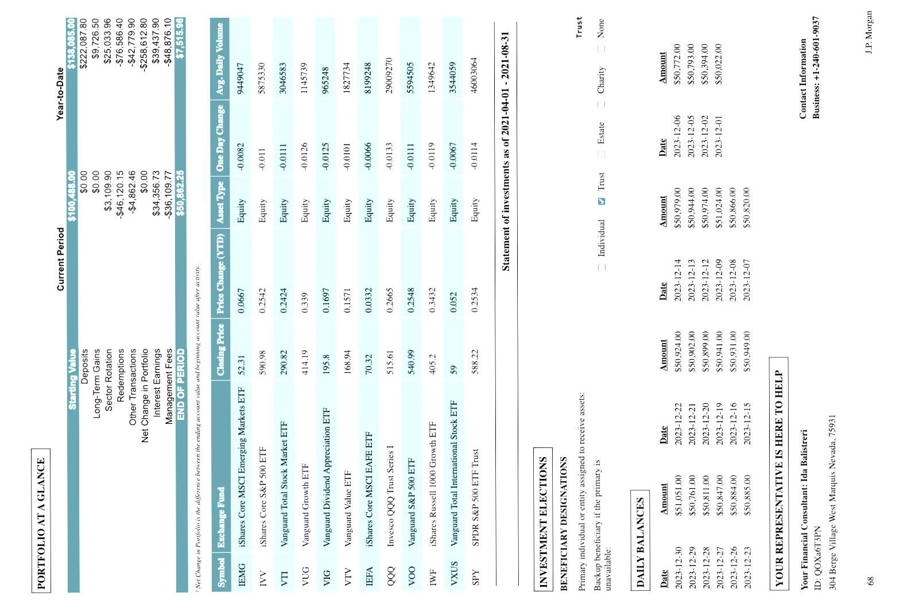

In [26]:
# Compare the model's output with the answer key for one document
import os, json, difflib, html
import pandas as pd
from datasets import load_dataset
from IPython.display import display, HTML

os.chdir('/content/drive/MyDrive/ocr_bench')
from ocr_eval import normalize          # same cleanup the scores use

ds = load_dataset("getomni-ai/ocr-benchmark", split="test")
idx = {rid: i for i, rid in enumerate(ds["id"])}
preds = {r["id"]: r for r in map(json.loads, filter(str.strip, open("ocr_results/predictions.jsonl")))}
scores = pd.read_csv("ocr_results/scores.csv").set_index("id")
print("Documents you can view:", sorted(preds))

def word_diff(pred, truth):
    a, b = pred.split(), truth.split()
    out = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
        if op == "equal":
            out.append(html.escape(" ".join(a[i1:i2]))); continue
        if i2 > i1:  # model wrote this, but it's not in the answer key
            out.append("<span style='background:#f8c8c8;color:#000;text-decoration:line-through'>" + html.escape(" ".join(a[i1:i2])) + "</span>")
        if j2 > j1:  # answer key has this, model missed or misread it
            out.append("<span style='background:#c8f0c8;color:#000'>" + html.escape(" ".join(b[j1:j2])) + "</span>")
    return " ".join(out)

def show(doc_id):
    row, p = ds[idx[doc_id]], preds[doc_id]
    meta = json.loads(row["metadata"])
    print(f"Document {doc_id} | {meta.get('format')} | {meta.get('documentQuality')}")
    if doc_id in scores.index:
        print(scores.loc[doc_id, ["similarity", "cer", "wer", "token_f1"]].round(3).to_dict())
    if p["error"]:
        print("MODEL CRASHED:", p["error"][:150])
    img = row["image"].copy(); img.thumbnail((900, 1400)); display(img)

    box = "white-space:pre-wrap;font-size:12px;border:1px solid #888;padding:8px;max-height:500px;overflow:auto;width:48%"
    display(HTML(f"""
    <div style='display:flex;gap:2%'>
      <div style='{box}'><b>MODEL OUTPUT</b><hr>{html.escape(p['prediction'])}</div>
      <div style='{box}'><b>ANSWER KEY</b><hr>{html.escape(row['true_markdown_output'])}</div>
    </div>
    <p><b>Word-by-word differences</b> (what the score sees):
      <span style='background:#f8c8c8;color:#000;text-decoration:line-through'>red = model wrote, not in answer</span>
      <span style='background:#c8f0c8;color:#000'>green = in answer, model missed</span></p>
    <div style='font-size:12px;line-height:1.7;border:1px solid #888;padding:8px;max-height:500px;overflow:auto'>
      {word_diff(normalize(p['prediction']), normalize(row['true_markdown_output']))}
    </div>"""))

show(711)   # change the number to look at another document